# Proiect – Partea A: Cine răspunde la campania de marketing?

**Set de date:** *Customer Personality Analysis* (Kaggle) – 2240 de clienți ai unui magazin.

**Planul notebook-ului (= cerințele):**

| # | Cerință | Secțiunea |
|---|---|---|
| 1 | Formularea problemei + analiza exploratorie (EDA) | 1, 2 |
| 2 | Preprocesare într-un pipeline (lipsă, codificare, scalare, data leakage) | 3, 4 |
| 3 | Dezechilibrul dintre clase | 5 |
| 4–6 | 3 modele (LogReg, **SVM**, **Random Forest** = ansamblu), train/test, k-fold CV, grid search, metrici | 6, 7, 8 |
| 7 | Interpretare, încrederea în rezultate, concluzii | 9, 10, 13 |
| + | A doua întrebare a setului: cât cheltuie un client (regresie) | 11 |
| + | Contribuție originală: pe cine sunăm dacă bugetul e limitat | 12 |

> Fiecare pas are trei întrebări: **Ce fac? – De ce? – De ce nu altceva?** Asta e și structura prezentării.

## 0. Importuri și setări

`SEED = 42` peste tot → rezultatele sunt **reproductibile** (dacă rulez din nou, obțin aceleași cifre).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

SEED = 42
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (8, 4)

## 1. Formularea problemei

**Context:** magazinul a trimis o campanie de marketing. Coloana `Response` = 1 dacă clientul **a acceptat oferta** din ultima campanie, 0 altfel.

**Problema:** *clasificare binară supervizată* – pe baza datelor despre client (venit, vârstă, copii, cât cheltuie, pe ce canale cumpără, campanii anterioare) prezicem dacă va răspunde (`Response = 1`).

**De ce e utilă:** dacă știm dinainte cine are șanse mari să răspundă, trimitem oferta doar lor → **costuri mai mici** și **mai puțini clienți deranjați**.

**De ce clasificare și nu regresie / clustering?** Ținta are doar două valori (da/nu) și avem eticheta pentru fiecare client → învățare supervizată, clasificare.

In [2]:
df = pd.read_csv("data/raw.csv")
print("Dimensiune:", df.shape)
df.head()

Dimensiune: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## 2. Analiza exploratorie a datelor (EDA)

Înainte de orice model mă uit la date: tipuri de coloane, valori lipsă, valori ciudate, distribuția țintei.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [4]:
print("Valori lipsă pe coloană:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nColoane cu o singură valoare (nu aduc informație):",
      [c for c in df.columns if df[c].nunique() == 1])

Valori lipsă pe coloană:
Income    24
dtype: int64

Coloane cu o singură valoare (nu aduc informație): ['Z_CostContact', 'Z_Revenue']


**Observații:**
- doar `Income` are valori lipsă (24 din 2240, ~1%) → le vom completa (imputare) **în pipeline**;
- `Z_CostContact` și `Z_Revenue` sunt constante → le eliminăm;
- `ID` e doar un identificator → îl eliminăm (altfel modelul ar putea „învăța” numere fără sens);
- `Education` și `Marital_Status` sunt text → trebuie codificate.

### 2.1 Distribuția țintei – sunt clasele echilibrate?

Response
0    1906
1     334
Name: count, dtype: int64

Procent: {0: 85.1, 1: 14.9}


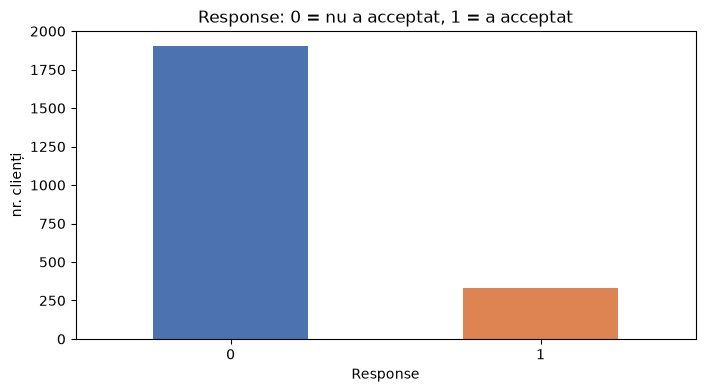

In [5]:
counts = df["Response"].value_counts()
print(counts)
print("\nProcent:", (df["Response"].value_counts(normalize=True) * 100).round(1).to_dict())

counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Response: 0 = nu a acceptat, 1 = a acceptat")
plt.xticks(rotation=0); plt.ylabel("nr. clienți"); plt.show()

**Doar ~15% dintre clienți au răspuns** → clase **dezechilibrate** (≈ 1 la 6).

Consecință importantă: un model care spune mereu „nu” ar avea **85% acuratețe** și ar fi complet inutil.
De aceea **acuratețea NU e o metrică bună aici** (revenim în secțiunea 7).

### 2.2 Variabile numerice – valori aberante

In [6]:
df[["Year_Birth", "Income", "Recency", "MntWines", "MntMeatProducts", "NumWebVisitsMonth"]].describe().round(1)

,Year_Birth,Income,Recency,MntWines,MntMeatProducts,NumWebVisitsMonth
count,2240.0,2216.0,2240.0,2240.0,2240.0,2240.0
mean,1968.8,52247.3,49.1,303.9,167.0,5.3
std,12.0,25173.1,29.0,336.6,225.7,2.4
min,1893.0,1730.0,0.0,0.0,0.0,0.0
25%,1959.0,35303.0,24.0,23.8,16.0,3.0
50%,1970.0,51381.5,49.0,173.5,67.0,6.0
75%,1977.0,68522.0,74.0,504.2,232.0,7.0
max,1996.0,666666.0,99.0,1493.0,1725.0,20.0


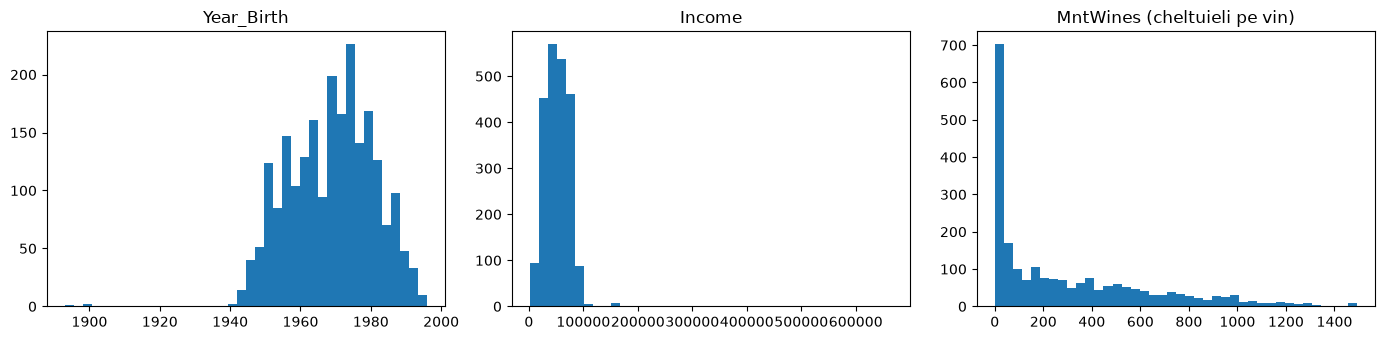

Născuți înainte de 1920: [1900, 1893, 1899]
Venituri > 200.000: [666666.0]


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(df["Year_Birth"], bins=40); axes[0].set_title("Year_Birth")
axes[1].hist(df["Income"].dropna(), bins=40); axes[1].set_title("Income")
axes[2].hist(df["MntWines"], bins=40); axes[2].set_title("MntWines (cheltuieli pe vin)")
plt.tight_layout(); plt.show()

print("Născuți înainte de 1920:", df.loc[df["Year_Birth"] < 1920, "Year_Birth"].tolist())
print("Venituri > 200.000:", df.loc[df["Income"] > 200_000, "Income"].tolist())

**Observații:**
- există clienți „născuți” în 1893–1900 (vârstă > 110 ani) → **erori de introducere**;
- un venit de 666.666 → tot eroare evidentă;
- cheltuielile sunt foarte asimetrice (mulți cheltuie puțin, puțini cheltuie mult) – normal pentru date de vânzări.

**Decizie:** elimin aceste câteva rânduri **imposibile** (reguli de bun simț, nu statistici calculate pe date → nu produce data leakage).

### 2.3 Cine răspunde? Rata de răspuns pe grupe

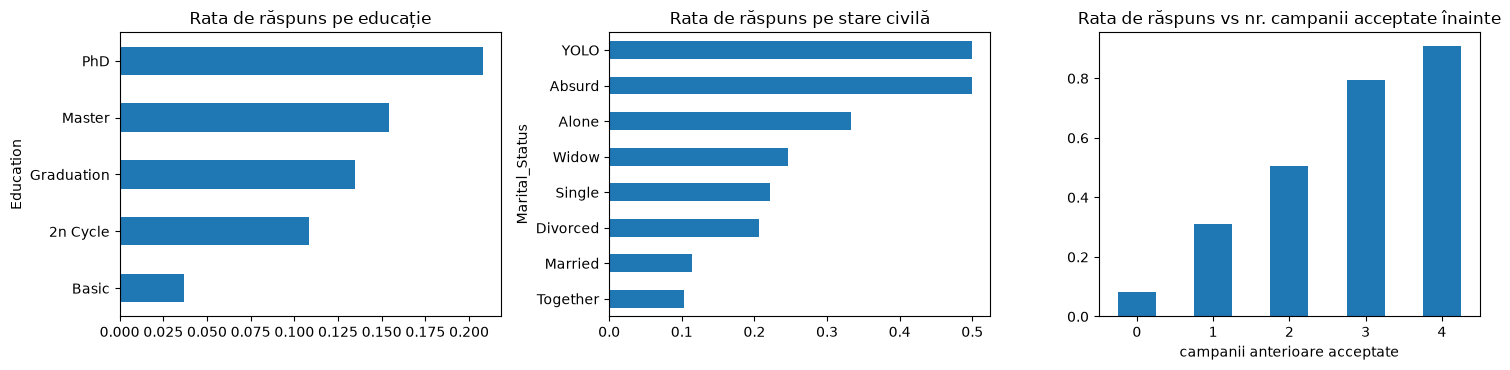

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
df.groupby("Education")["Response"].mean().sort_values().plot(kind="barh", ax=axes[0], title="Rata de răspuns pe educație")
df.groupby("Marital_Status")["Response"].mean().sort_values().plot(kind="barh", ax=axes[1], title="Rata de răspuns pe stare civilă")
camp = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5"]
df.groupby(df[camp].sum(axis=1))["Response"].mean().plot(kind="bar", ax=axes[2],
        title="Rata de răspuns vs nr. campanii acceptate înainte")
axes[2].set_xlabel("campanii anterioare acceptate"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

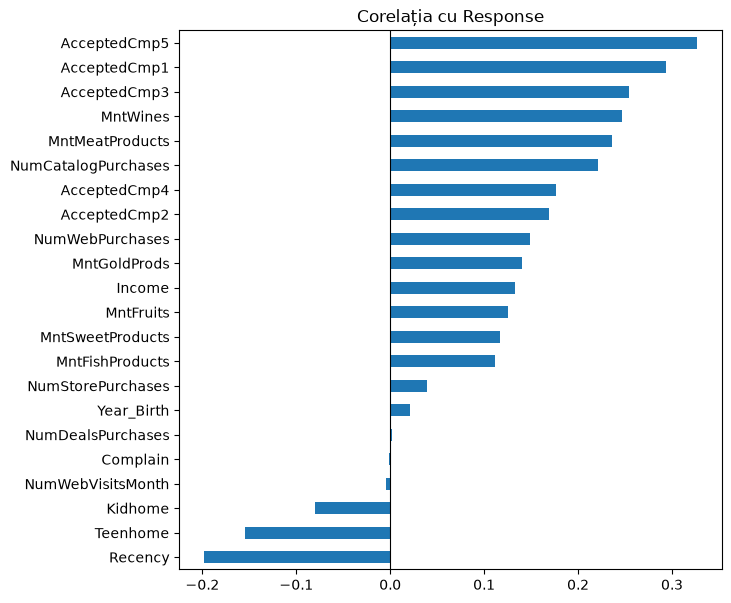

In [9]:
# corelația fiecărei coloane numerice cu ținta
num = df.select_dtypes("number").drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
corr = num.corr()["Response"].drop("Response").sort_values()
corr.plot(kind="barh", figsize=(7, 7), title="Corelația cu Response")
plt.axvline(0, color="k", lw=0.8); plt.show()

**Ce am aflat din EDA:**
- clienții care **au acceptat campanii anterioare** răspund mult mai des (cel mai puternic semnal);
- cei care cumpără mult (vin, carne, din catalog) și au venit mare răspund mai des;
- `Recency` (zile de la ultima cumpărare) e corelat **negativ**: clienții activi recent răspund mai des;
- clienții cu copii acasă (`Kidhome`, `Teenhome`) răspund mai rar;
- `Single`/`Divorced`/`Widow` răspund mai des decât `Married`/`Together`;
- categoriile `Alone`, `Absurd`, `YOLO` au 2–3 persoane → le grupez în `Other` (prea rare ca modelul să învețe ceva din ele).

## 3. Curățare și atribute noi

Aici fac doar transformări **rând cu rând** (care nu folosesc statistici din tot setul) → sigure din punct de vedere al data leakage, pot fi făcute înainte de împărțirea train/test.

- `Age` = 2014 − `Year_Birth` (datele sunt din 2014; vârsta e mai intuitivă decât anul);
- `Customer_Days` = câte zile e clientul înscris (din `Dt_Customer`, care e o dată – modelul nu poate folosi direct o dată);
- `Children` = `Kidhome` + `Teenhome`;
- `MntTotal` = suma tuturor cheltuielilor;
- `TotalPurchases` = numărul total de cumpărături;
- `PrevAccepted` = câte campanii anterioare a acceptat.

**De ce atribute noi?** Rezumă informația în forme ușor de interpretat (ex. „cât cheltuie în total”) și ajută modelele liniare.

In [10]:
data = df.copy()

# 1) eliminăm rândurile imposibile (vârstă > 100, venit absurd)
data = data[(data["Year_Birth"] >= 1920) & ~(data["Income"] > 200_000)]

# 2) atribute noi
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], format="%d-%m-%Y")
data["Age"] = 2014 - data["Year_Birth"]
data["Customer_Days"] = (pd.Timestamp("2014-12-31") - data["Dt_Customer"]).dt.days
data["Children"] = data["Kidhome"] + data["Teenhome"]
mnt = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
data["MntTotal"] = data[mnt].sum(axis=1)
data["TotalPurchases"] = data[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
data["PrevAccepted"] = data[camp].sum(axis=1)

# 3) categorii rare -> "Other"
data["Marital_Status"] = data["Marital_Status"].replace({"Alone": "Other", "Absurd": "Other", "YOLO": "Other"})

# 4) eliminăm coloanele inutile
data = data.drop(columns=["ID", "Year_Birth", "Dt_Customer", "Z_CostContact", "Z_Revenue"])

print("Rânduri eliminate:", len(df) - len(data))
print("Dimensiune finală:", data.shape)
print("Income lipsă (rămâne pentru pipeline):", data["Income"].isna().sum())

Rânduri eliminate: 4
Dimensiune finală: (2236, 30)
Income lipsă (rămâne pentru pipeline): 24


## 4. Împărțirea train/test și pipeline-ul de preprocesare

### 4.1 Train / test
- **80% train, 20% test**, cu `stratify=y` → ambele părți păstrează aceeași proporție de 15% clienți care răspund.
- Setul de **test e pus deoparte și folosit O SINGURĂ DATĂ, la final**. Toate deciziile (model, hiperparametri) se iau doar pe train, cu cross-validation.

**De ce stratificat?** Cu o clasă rară, o împărțire la întâmplare ar putea pune, de exemplu, 10% pozitive în test și 17% în train → comparații nedrepte.

In [11]:
X = data.drop(columns="Response")
y = data["Response"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| % pozitive:", round(y_train.mean() * 100, 1))
print("Test :", X_test.shape,  "| % pozitive:", round(y_test.mean() * 100, 1))

Train: (1788, 29) | % pozitive: 14.9
Test : (448, 29) | % pozitive: 15.0


### 4.2 Pipeline-ul de preprocesare

| Tip coloană | Pas | De ce | De ce nu altceva |
|---|---|---|---|
| numerice | `SimpleImputer(median)` | completează cele ~24 de `Income` lipsă | **mediana** e robustă la valori extreme (venitul e asimetric); media ar fi trasă în sus. Nu ștergem rândurile ca să nu pierdem date. |
| numerice | `StandardScaler` | aduce toate coloanele la medie 0, deviație 1 | **SVM și Regresia Logistică depind de distanțe/mărimea coeficienților**: fără scalare, `Income` (~50.000) ar domina `Kidhome` (0–2). Random Forest nu are nevoie, dar nu îl deranjează. |
| categoriale | `SimpleImputer(most_frequent)` + `OneHotEncoder` | transformă textul în coloane 0/1 | Nu folosim codificare 0,1,2,3… (ordinal) pentru că ar inventa o ordine falsă (ex. „Married < Single”). `handle_unknown="ignore"` → nu crapă dacă apare o categorie nouă în test. |

In [12]:
num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numerice  :", len(num_cols), num_cols)
print("Categoriale:", cat_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
preprocess

Numerice  : 27 ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Age', 'Customer_Days', 'Children', 'MntTotal', 'TotalPurchases', 'PrevAccepted']
Categoriale: ['Education', 'Marital_Status']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [13]:
# verificare: după preprocesare nu mai există valori lipsă și totul e numeric
Xt = preprocess.fit_transform(X_train)
print("Formă după preprocesare:", Xt.shape, "| NaN rămase:", np.isnan(Xt).sum())

Formă după preprocesare: (1788, 38) | NaN rămase: 0


#### Exemplu: un client real, înainte și după preprocesare

Iau primul client din train și arăt ce face pipeline-ul cu el:
- **numericele** (`Income`, `Recency`, `Kidhome`) devin „cât de departe e clientul de cel obișnuit”: 0 = ca media, plus = peste medie, minus = sub medie;
- **textul** (`Education`, `Marital_Status`) devine coloane 0/1 (**One-Hot**): pune 1 la categoria clientului și 0 la toate celelalte.

Din 29 de coloane se fac 38: 27 numerice + 5 pentru educație + 6 pentru starea civilă.

In [14]:
from IPython.display import HTML, display

client = X_train.iloc[0]                                     # primul client din train
dupa = pd.Series(preprocess.transform(X_train.iloc[[0]])[0],  # același client, după pipeline
                 index=[n.split("__")[1] for n in preprocess.get_feature_names_out()])

# rândurile colorate = aceleași informații, înainte și după
colorate_inainte = ["Education", "Marital_Status", "Income", "Kidhome", "Recency"]
colorate_dupa = ["Income", "Kidhome", "Recency", "Education_Graduation", "Marital_Status_Divorced"]

def scrie_inainte(nume, v):
    return f"{v:g}" if isinstance(v, (int, float, np.number)) else str(v)

def scrie_dupa(nume, v):
    if nume.startswith(("Education_", "Marital_Status_")):
        return str(int(v))                                   # One-Hot: 0 sau 1
    return f"{v:.3f}".replace(".", ",")                     # numerice scalate

def tabel(serie, titlu, colorate, scrie):
    randuri = ""
    for nume, v in serie.items():
        fundal = "background: rgba(11, 122, 87, 0.25);" if nume in colorate else ""
        randuri += (f"<tr style='{fundal}'><td style='text-align:left; padding:4px 10px'>{nume}</td>"
                    f"<td style='text-align:right; padding:4px 10px; font-family:monospace'>{scrie(nume, v)}</td></tr>")
    return (f"<div style='flex:1; min-width:260px'><p style='font-family:monospace; letter-spacing:1px'>{titlu}</p>"
            f"<table style='width:100%; border-collapse:collapse'>{randuri}</table></div>")

display(HTML("<p><b>Un client real din train, înainte și după pipeline</b><br>"
             "Rândurile colorate sunt aceleași informații, transformate. "
             "Textul a devenit coloane 0/1, iar numerele au fost scalate.</p>"
             "<div style='display:flex; gap:32px; flex-wrap:wrap'>"
             + tabel(client, f"ÎNAINTE · {len(client)} DE COLOANE", colorate_inainte, scrie_inainte)
             + tabel(dupa, f"DUPĂ · {len(dupa)} DE COLOANE", colorate_dupa, scrie_dupa)
             + "</div>"))

Education,Graduation
Marital_Status,Divorced
Income,57136
Kidhome,0
Teenhome,0
Recency,18
MntWines,267
MntFruits,140
MntMeatProducts,599
MntFishProducts,34
MntSweetProducts,12


**Cum se citește:**
- `Income` 57.136 → **0,244**: puțin peste venitul mediu din train (51.948);
- `Recency` 18 zile → **−1,071**: a cumpărat mult mai recent decât clientul obișnuit (49 de zile);
- `Kidhome` 0 → **−0,829**: mai puțini copii mici decât media (0,45);
- `Education` = Graduation → `Education_Graduation = 1`, celelalte 4 coloane de educație = 0;
- `Marital_Status` = Divorced → `Marital_Status_Divorced = 1`, celelalte 5 = 0.

### 4.3 Cum evit **data leakage**
*Data leakage* = informație din datele de test ajunge (direct sau indirect) în antrenare → scoruri prea optimiste, care nu se mai confirmă în realitate.

1. Împart train/test **înainte** de orice pas care „învață” din date (mediană, medie, deviație standard).
2. Pun preprocesarea **în același `Pipeline` cu modelul**. Astfel, în fiecare fold de cross-validation, mediana și scalarea sunt calculate **doar pe fold-urile de antrenare**, apoi aplicate pe fold-ul de validare.
3. Dacă aș fi scalat tot setul înainte de split → mediile ar conține și informație din test = leakage.

Pipeline-ul propriu-zis (preprocesare + model) se construiește în capitolele 5 și 6: `Pipeline([("prep", preprocess), ("model", ...)])`.

### 4.4 Cross-validation
Folosesc **`StratifiedKFold` cu k = 5**: train-ul e împărțit în 5 bucăți; de 5 ori antrenez pe 4 și validez pe a 5-a, apoi fac media.

- **De ce CV și nu un singur set de validare?** Cu doar ~330 de pozitive în train, un singur split ar da un scor „norocos” sau „ghinionist”. Media pe 5 fold-uri e mai stabilă și văd și deviația standard.
- **De ce stratificat?** Fiecare fold păstrează ~15% pozitive.
- **De ce 5 și nu 10?** Compromis bun între stabilitate și timp de calcul (grid search-ul rulează modelul de 5 × nr. combinații ori).

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

## 5. Tratarea dezechilibrului dintre clase

Am 85% / 15%. Un model antrenat „normal” tinde să favorizeze clasa majoritară (spune des „nu”) și ratează clienții care ar răspunde – exact cei care ne interesează.

Compar 3 variante pe aceeași Regresie Logistică, cu CV pe train:
1. **nimic** (baseline);
2. **ponderi de clasă** (`class_weight="balanced"`) – greșelile pe clasa rară costă de ~6 ori mai mult;
3. **reeșantionare SMOTE** – generez exemple sintetice din clasa minoritară. SMOTE e pus **în pipeline-ul din `imblearn`**, deci se aplică **doar pe fold-urile de antrenare** (dacă l-aș aplica înainte de CV, exemplele sintetice ar „scăpa” în validare = leakage).

Metrica comparată: **F1 și recall pe clasa 1** (cât din clienții care răspund găsim) + **ROC-AUC**.

In [16]:
variante = {
    "Fără tratare":      Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000))]),
    "class_weight":      Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "SMOTE":             ImbPipeline([("prep", preprocess), ("smote", SMOTE(random_state=SEED)),
                                      ("model", LogisticRegression(max_iter=2000))]),
}

rez = []
for nume, pipe in variante.items():
    r = {"Variantă": nume}
    for m in ["roc_auc", "f1", "recall", "precision"]:
        r[m] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring=m).mean()
    rez.append(r)
pd.DataFrame(rez).set_index("Variantă").round(3)

,roc_auc,f1,recall,precision
Variantă,,,,
Fără tratare,0.903,0.588,0.505,0.707
class_weight,0.904,0.584,0.805,0.458
SMOTE,0.901,0.595,0.798,0.474


**Interpretare:**
- **ROC-AUC rămâne aproape la fel** – capacitatea modelului de a *ordona* clienții (cine e mai probabil să răspundă) nu se schimbă;
- ce se schimbă e **pragul de decizie**: fără tratare modelul găsește puțini dintre cei care răspund (recall mic); cu `class_weight` sau SMOTE **recall-ul crește mult**, cu prețul unei precizii mai mici (mai multe oferte trimise „degeaba”);
- pentru o campanie de marketing, a rata un client interesat costă mai mult decât a trimite un email în plus → prefer **recall mai mare**.

**Decizia: `class_weight="balanced"`.** Dă rezultate similare cu SMOTE, dar e **mai simplu** (nu creează date artificiale, nu adaugă un pas în plus și e mai rapid). Îl folosesc la toate modelele care îl suportă (LogReg, SVM, Random Forest).

## 6. Modelele și alegerea hiperparametrilor (Grid Search + 5-fold CV)

| Model | De ce l-am ales | Hiperparametri căutați |
|---|---|---|
| **Regresie Logistică** | model **simplu, liniar, interpretabil** → punct de referință (baseline). Dacă modelele complicate nu-l bat, nu merită complicația. | `C` = cât de puternică e regularizarea (mic = model mai simplu) |
| **SVM (SVC, kernel RBF)** – *obligatoriu* | caută granița cu **marginea maximă** între clase; kernelul RBF permite granițe **neliniare** | `C` (cât de mult penalizăm greșelile), `gamma` (cât de „locală” e influența fiecărui punct) |
| **Random Forest** – *ansamblu, obligatoriu* | **multe arbori de decizie** antrenați pe eșantioane diferite, apoi vot. Captează interacțiuni și neliniarități, e robust la outlieri și dă importanța atributelor. | `n_estimators`, `max_depth`, `min_samples_leaf` (controlează overfitting-ul) |

Plus un **DummyClassifier** (ghicește după proporție) – ca să arăt că modelele chiar învață ceva.

**De ce Random Forest și nu Gradient Boosting?** Ambele sunt ansambluri; Random Forest e mai ușor de reglat (mai puțini hiperparametri sensibili) și greu de supraantrenat. **De ce kernel RBF și nu liniar la SVM?** Liniarul ar fi aproape identic cu Regresia Logistică; RBF aduce ceva nou (neliniaritate). Am inclus totuși `linear` în grid ca să las datele să decidă.

**Metrica după care aleg hiperparametrii: ROC-AUC.** Nu depinde de prag și funcționează corect cu clase dezechilibrate (spre deosebire de acuratețe).

In [17]:
modele = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}),
    "SVM": (
        SVC(class_weight="balanced", random_state=SEED),
        [{"model__kernel": ["rbf"], "model__C": [0.1, 1, 10, 100], "model__gamma": [0.001, 0.01, 0.1, 1]},
         {"model__kernel": ["linear"], "model__C": [0.1, 1]}]),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
        {"model__n_estimators": [300], "model__max_depth": [3, 5, 10, None],
         "model__min_samples_leaf": [1, 5, 10]}),
}

cele_mai_bune = {}
cautari = {}      # păstrăm toate căutările pentru studiile de senzitivitate (cap. 10)
rezumat_cv = []
for nume, (model, grid) in modele.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    cele_mai_bune[nume] = gs.best_estimator_
    cautari[nume] = gs
    i = gs.best_index_
    rezumat_cv.append({"Model": nume,
                       "ROC-AUC CV (medie)": gs.cv_results_["mean_test_score"][i],
                       "± std": gs.cv_results_["std_test_score"][i],
                       "Cei mai buni parametri": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
    print(f"{nume:20s} ROC-AUC CV = {gs.best_score_:.3f}  | {gs.best_params_}")

# baseline Dummy
dummy = Pipeline([("prep", preprocess), ("model", DummyClassifier(strategy="stratified", random_state=SEED))])
s = cross_val_score(dummy, X_train, y_train, cv=cv, scoring="roc_auc")
cele_mai_bune["Dummy (baseline)"] = dummy.fit(X_train, y_train)
rezumat_cv.append({"Model": "Dummy (baseline)", "ROC-AUC CV (medie)": s.mean(), "± std": s.std(), "Cei mai buni parametri": "-"})

tabel_cv = pd.DataFrame(rezumat_cv).set_index("Model").sort_values("ROC-AUC CV (medie)", ascending=False)
tabel_cv.round(3)

Logistic Regression  ROC-AUC CV = 0.904  | {'model__C': 1}


SVM                  ROC-AUC CV = 0.902  | {'model__C': 10, 'model__gamma': 0.001, 'model__kernel': 'rbf'}


Random Forest        ROC-AUC CV = 0.894  | {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}


,ROC-AUC CV (medie),± std,Cei mai buni parametri
Model,,,
Logistic Regression,0.904,0.019,{'C': 1}
SVM,0.902,0.019,"{'C': 10, 'gamma': 0.001, 'kernel': 'rbf'}"
Random Forest,0.894,0.004,"{'max_depth': None, 'min_samples_leaf': 1, 'n_..."
Dummy (baseline),0.494,0.017,-


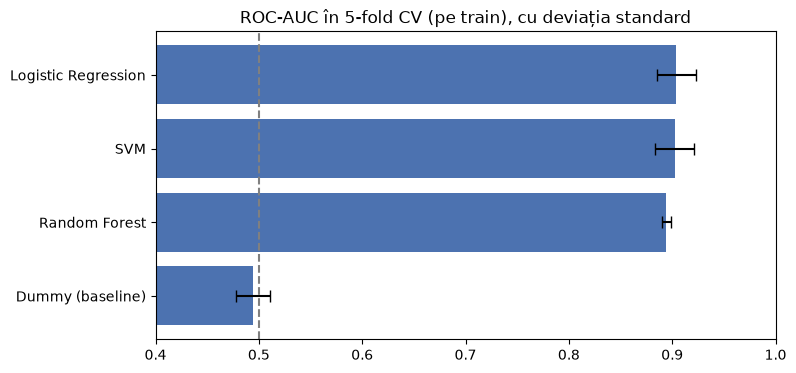

In [18]:
t = tabel_cv.sort_values("ROC-AUC CV (medie)")
plt.barh(t.index, t["ROC-AUC CV (medie)"], xerr=t["± std"], color="#4C72B0", capsize=4)
plt.axvline(0.5, ls="--", c="gray"); plt.xlim(0.4, 1)
plt.title("ROC-AUC în 5-fold CV (pe train), cu deviația standard"); plt.show()

**Interpretare:**
- toate cele 3 modele sunt **mult peste Dummy (≈0.5 = ghicit la întâmplare)** → chiar au învățat ceva;
- diferențele dintre modele sunt mici și comparabile cu deviația standard dintre fold-uri → niciun model nu e „net superior”;
- Regresia Logistică ține pasul cu modelele complexe → relația dintre atribute și răspuns e în mare parte **aproape liniară** (venit, cheltuieli, campanii anterioare → mai multe șanse).

## 7. Evaluarea finală pe setul de test

Abia acum folosesc setul de test – **o singură dată**, pentru modelele deja alese.

**Metricile alese și de ce:**
- **ROC-AUC** – cât de bine *ordonează* modelul clienții (1 = perfect, 0.5 = la întâmplare). Nu depinde de prag.
- **PR-AUC (Average Precision)** – ca ROC-AUC, dar concentrată pe clasa rară; mai strictă la dezechilibru. Referința „la întâmplare” = 0.15, nu 0.5.
- **Recall (clasa 1)** – din clienții care ar răspunde, pe câți îi găsim? *(cel mai important pentru business)*
- **Precision (clasa 1)** – din cei cărora le trimitem oferta, câți răspund?
- **F1** – echilibrul dintre precision și recall.
- **Acuratețea** o afișez doar ca să arăt că **e înșelătoare** (Dummy-ul o are mare).

In [19]:
def scor_continuu(model, X):
    # SVC nu are predict_proba (fără probability=True), dar decision_function e suficient pentru AUC
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

rezultate_test = []
for nume, model in cele_mai_bune.items():
    y_pred = model.predict(X_test)
    s = scor_continuu(model, X_test)
    rezultate_test.append({"Model": nume,
                           "ROC-AUC": roc_auc_score(y_test, s),
                           "PR-AUC": average_precision_score(y_test, s),
                           "Recall": recall_score(y_test, y_pred),
                           "Precision": precision_score(y_test, y_pred, zero_division=0),
                           "F1": f1_score(y_test, y_pred),
                           "Accuracy": accuracy_score(y_test, y_pred)})
tabel_test = pd.DataFrame(rezultate_test).set_index("Model").sort_values("ROC-AUC", ascending=False)
tabel_test.round(3)

,ROC-AUC,PR-AUC,Recall,Precision,F1,Accuracy
Model,,,,,,
Logistic Regression,0.892,0.614,0.761,0.440,0.557,0.819
SVM,0.890,0.620,0.761,0.447,0.564,0.824
Random Forest,0.883,0.603,0.478,0.604,0.533,0.875
Dummy (baseline),0.513,0.153,0.179,0.171,0.175,0.748


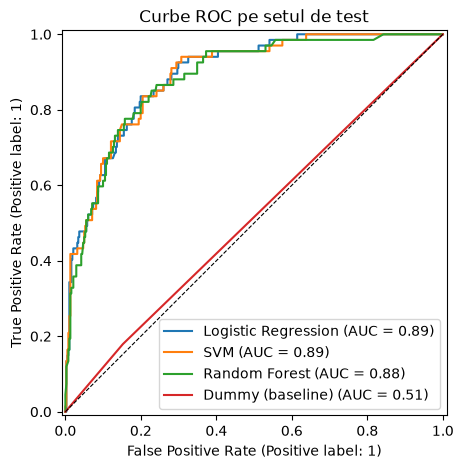

In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
for nume, model in cele_mai_bune.items():
    RocCurveDisplay.from_predictions(y_test, scor_continuu(model, X_test), name=nume, ax=ax)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_title("Curbe ROC pe setul de test"); plt.show()

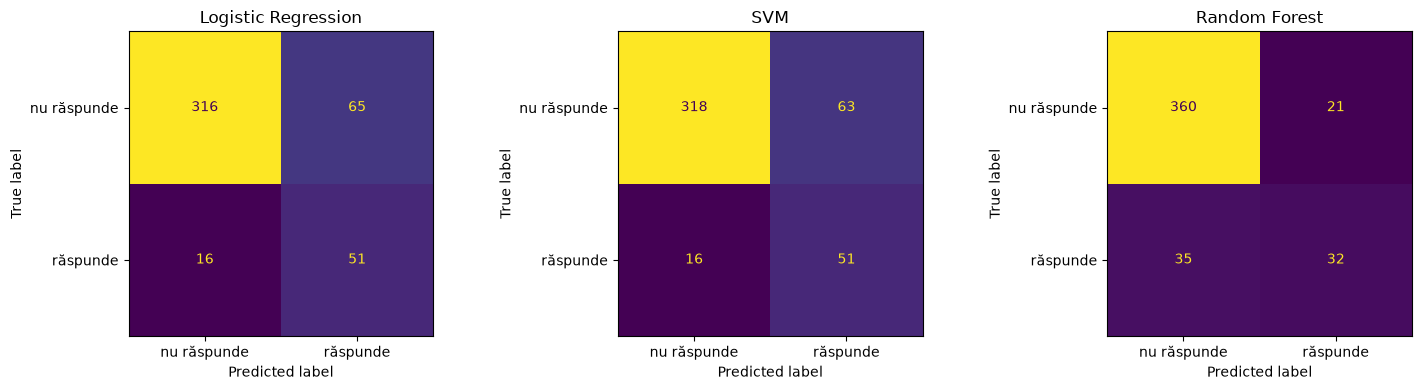

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nume in zip(axes, ["Logistic Regression", "SVM", "Random Forest"]):
    ConfusionMatrixDisplay.from_estimator(cele_mai_bune[nume], X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["nu răspunde", "răspunde"])
    ax.set_title(nume)
plt.tight_layout(); plt.show()

**Cum citesc matricea de confuzie:** pe diagonală sunt predicțiile corecte. Colțul **stânga-jos** = clienți care ar fi răspuns, dar modelul i-a ratat (*false negatives*) – vrem cât mai puțini. Colțul **dreapta-sus** = oferte trimise degeaba (*false positives*) – mai puțin grav (costul unui email).

## 8. Comparația modelelor

In [22]:
cmp = tabel_cv[["ROC-AUC CV (medie)"]].join(tabel_test[["ROC-AUC", "PR-AUC", "Recall", "Precision", "F1"]])
cmp.columns = ["ROC-AUC (CV train)", "ROC-AUC (test)", "PR-AUC (test)", "Recall (test)", "Precision (test)", "F1 (test)"]
cmp.round(3)

,ROC-AUC (CV train),ROC-AUC (test),PR-AUC (test),Recall (test),Precision (test),F1 (test)
Model,,,,,,
Logistic Regression,0.904,0.892,0.614,0.761,0.440,0.557
SVM,0.902,0.890,0.620,0.761,0.447,0.564
Random Forest,0.894,0.883,0.603,0.478,0.604,0.533
Dummy (baseline),0.494,0.513,0.153,0.179,0.171,0.175


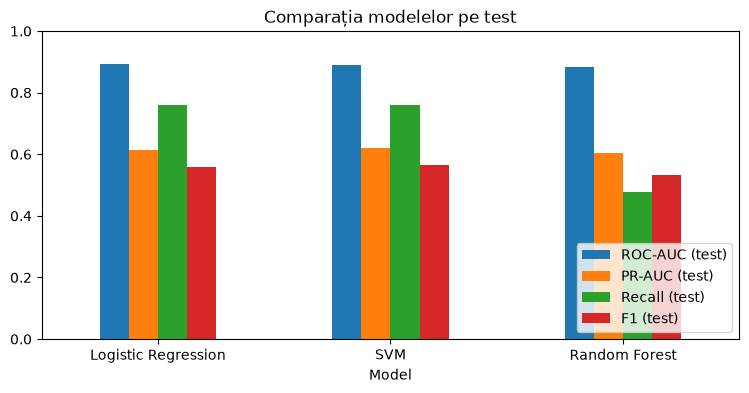

In [23]:
cmp.drop(index="Dummy (baseline)")[["ROC-AUC (test)", "PR-AUC (test)", "Recall (test)", "F1 (test)"]].plot(
    kind="bar", figsize=(9, 4), rot=0, ylim=(0, 1), title="Comparația modelelor pe test")
plt.legend(loc="lower right"); plt.show()

**Ce observ:**
- **Scorul pe test e apropiat de scorul din CV** → estimarea din cross-validation a fost corectă și **nu avem overfitting** puternic (dacă testul ar fi fost mult mai slab, ar fi fost un semnal de alarmă sau de leakage);
- **Regresia Logistică și SVM sunt practic la egalitate** (ROC-AUC ≈ 0.89, recall ≈ 0.76: găsesc ~3 din 4 clienți care răspund). Diferența de 0.002 e mult sub deviația standard din CV (~0.02);
- **Random Forest** are ROC-AUC apropiat, dar **recall mic (~0.48)**: deși i-am dat `class_weight="balanced"`, arborii adânci (`max_depth=None`) „memorează” train-ul, iar ponderile contează puțin → spune „da” rar. Are în schimb **cea mai mare precizie**. Pragul lui ar trebui coborât dacă vrem să-l folosim;
- **Dummy** are acuratețe ~75% și totuși ROC-AUC ≈ 0.5 și F1 foarte mic → confirmă că **acuratețea nu e metrica potrivită** (iar Random Forest are cea mai mare acuratețe, deși ratează jumătate din clienții interesați!).

**Ce model aleg? Regresia Logistică.** Are aceleași scoruri ca SVM (în CV, pe test și pe 10 împărțiri diferite – vezi 10.2), dar e **mai simplă, mai rapidă și explicabilă**: pot arăta unui manager de marketing exact ce atribute cresc sau scad șansa de răspuns. SVM-ul nu aduce un câștig care să justifice complexitatea în plus.

## 9. Interpretarea rezultatelor – ce atribute contează?

Folosesc **permutation importance** pe setul de test: amestec aleator valorile unei coloane și văd cât scade ROC-AUC. Dacă scade mult → modelul se bazează pe acea coloană.

**De ce permutation importance și nu `feature_importances_` din Random Forest?** Funcționează la fel pentru **orice model** (inclusiv SVM, care nu are importanțe proprii) și se calculează pe coloanele originale, nu pe cele one-hot → mai ușor de citit.

Model analizat: Logistic Regression


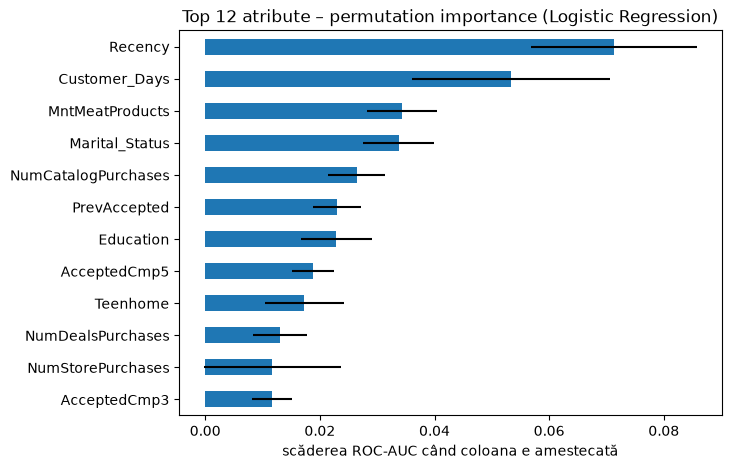

Recency                0.071
Customer_Days          0.053
MntMeatProducts        0.034
Marital_Status         0.034
NumCatalogPurchases    0.026
PrevAccepted           0.023
Education              0.023
AcceptedCmp5           0.019
dtype: float64


In [24]:
nume_model = tabel_test.drop(index="Dummy (baseline)").index[0]   # cel mai bun model pe test
print("Model analizat:", nume_model)
pi = permutation_importance(cele_mai_bune[nume_model], X_test, y_test, scoring="roc_auc",
                            n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.tail(12).plot(kind="barh", figsize=(7, 5), xerr=pd.Series(pi.importances_std, index=X_test.columns)[imp.tail(12).index],
                  title=f"Top 12 atribute – permutation importance ({nume_model})")
plt.xlabel("scăderea ROC-AUC când coloana e amestecată"); plt.show()
print(imp.sort_values(ascending=False).head(8).round(3))

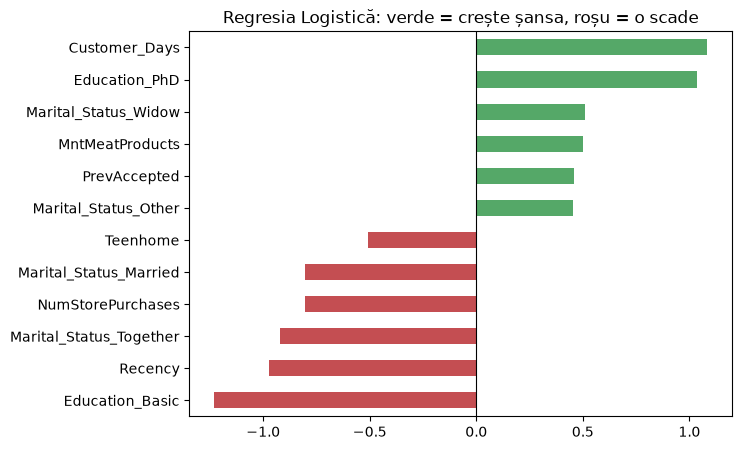

In [25]:
# Sensul efectului: coeficienții Regresiei Logistice (atributele sunt scalate, deci comparabile)
lr = cele_mai_bune["Logistic Regression"]
nume_coloane = lr.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr.named_steps["model"].coef_[0], index=nume_coloane).sort_values()
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
pd.concat([coef.head(6), coef.tail(6)]).plot(kind="barh", figsize=(7, 5),
        color=["#C44E52"] * 6 + ["#55A868"] * 6, title="Regresia Logistică: verde = crește șansa, roșu = o scade")
plt.axvline(0, c="k", lw=0.8); plt.show()

**Interpretare (în limbaj de business):**
- **`Recency`** e cel mai important: cu cât a trecut mai mult de la ultima cumpărare, cu atât șansa scade → clienții *activi recent* sunt ținta bună;
- **vechimea clientului (`Customer_Days`)**: clienții mai vechi răspund mai des;
- **cheltuielile pe carne** și **cumpărăturile din catalog** cresc șansa (clienți „valoroși”);
- **campaniile anterioare acceptate** contează mult, dar importanța lor e *împărțită* între mai multe coloane care spun același lucru (`PrevAccepted`, `AcceptedCmp1…5`) – de aceea fiecare pare mică luată separat;
- starea civilă **Married/Together** scade șansa, iar **Single/Divorced/Widow** o cresc; doctoratul (`PhD`) o crește;
- rezultatele confirmă ce am văzut în EDA (secțiunea 2.3) → modelul e coerent cu intuiția, nu a învățat ceva „ciudat”.

> Atenție la coeficienți: coloanele corelate între ele (ex. `Kidhome`, `Teenhome`, `Children`) își „împart” efectul, așa că semnul unui coeficient individual poate fi înșelător. De aceea mă bazez în primul rând pe permutation importance.

## 10. Cât de sigure sunt rezultatele?

### 10.1 Senzitivitatea la hiperparametri

Din grid search am păstrat scorul **fiecărei** combinații (pe train și pe validare). Așa văd nu doar „care e cel mai bun”, ci și **cât de mult contează** fiecare hiperparametru și unde apare overfitting-ul (scor mare pe train, mic pe validare).

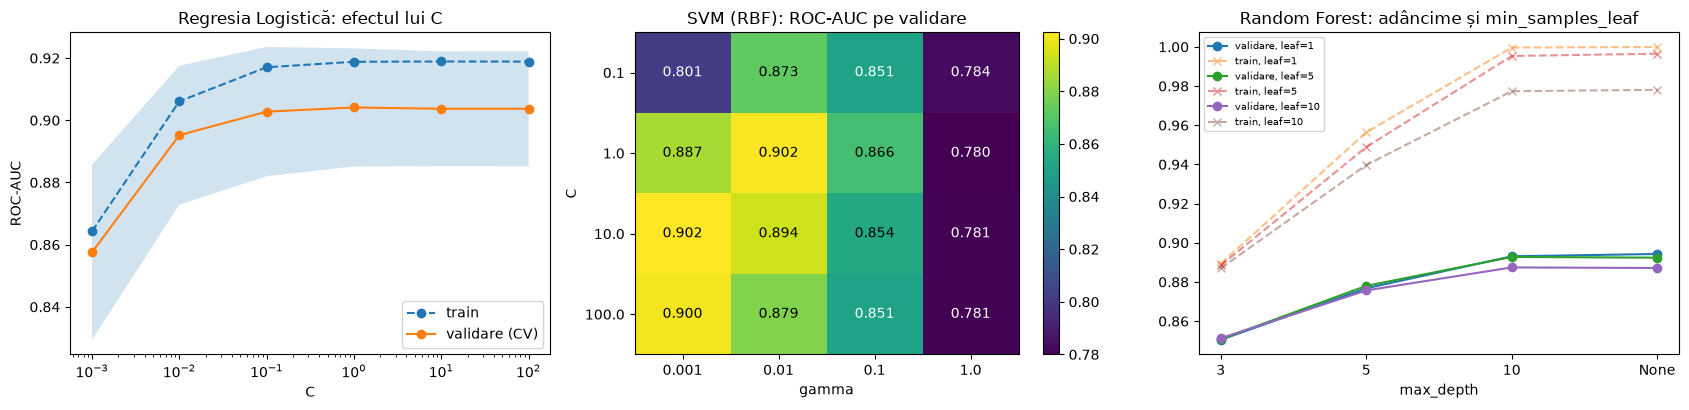

SVM (RBF) – ROC-AUC pe validare:
gamma  0.001  0.010  0.100  1.000
C                                
0.1    0.801  0.873  0.851  0.784
1.0    0.887  0.902  0.866  0.780
10.0   0.902  0.894  0.854  0.781
100.0  0.900  0.879  0.851  0.781

Random Forest – ROC-AUC validare / train:
                 mean_test_score                      mean_train_score         \
depth                         10      3      5   None               10      3   
min_samples_leaf                                                                
1                          0.893  0.850  0.877  0.894            1.000  0.889   
5                          0.893  0.851  0.878  0.892            0.995  0.888   
10                         0.887  0.851  0.876  0.887            0.977  0.887   

                                
depth                 5   None  
min_samples_leaf                
1                 0.956  1.000  
5                 0.949  0.997  
10                0.940  0.978  

Regresia Logistică:
         C  me

In [26]:
def rezultate(nume):
    r = pd.DataFrame(cautari[nume].cv_results_)
    r.columns = [c.replace("param_model__", "") for c in r.columns]
    return r

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))

# (a) Regresia Logistică: ROC-AUC în funcție de C
r = rezultate("Logistic Regression").sort_values("C")
axes[0].plot(r["C"], r["mean_train_score"], "o--", label="train")
axes[0].plot(r["C"], r["mean_test_score"], "o-", label="validare (CV)")
axes[0].fill_between(r["C"].astype(float), r["mean_test_score"] - r["std_test_score"],
                     r["mean_test_score"] + r["std_test_score"], alpha=0.2)
axes[0].set_xscale("log"); axes[0].set_xlabel("C"); axes[0].set_ylabel("ROC-AUC")
axes[0].set_title("Regresia Logistică: efectul lui C"); axes[0].legend()

# (b) SVM RBF: hartă C x gamma
r = rezultate("SVM"); r = r[r["kernel"] == "rbf"]
h = r.pivot_table(index="C", columns="gamma", values="mean_test_score")
im = axes[1].imshow(h.values, cmap="viridis", aspect="auto")
axes[1].set_xticks(range(len(h.columns)), h.columns); axes[1].set_yticks(range(len(h.index)), h.index)
axes[1].set_xlabel("gamma"); axes[1].set_ylabel("C"); axes[1].set_title("SVM (RBF): ROC-AUC pe validare")
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        axes[1].text(j, i, f"{h.values[i, j]:.3f}", ha="center", va="center",
                     color="white" if h.values[i, j] < h.values.max() - 0.05 else "black")
plt.colorbar(im, ax=axes[1])

# (c) Random Forest: adâncimea arborilor
r = rezultate("Random Forest")
r["depth"] = r["max_depth"].astype(object).where(r["max_depth"].notna(), "None").astype(str)
ordine = ["3", "5", "10", "None"]
for leaf, g in r.groupby("min_samples_leaf"):
    g = g.set_index("depth").loc[ordine]
    axes[2].plot(ordine, g["mean_test_score"], "o-", label=f"validare, leaf={leaf}")
    axes[2].plot(ordine, g["mean_train_score"], "x--", alpha=0.5, label=f"train, leaf={leaf}")
axes[2].set_xlabel("max_depth"); axes[2].set_title("Random Forest: adâncime și min_samples_leaf")
axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

print("SVM (RBF) – ROC-AUC pe validare:"); print(h.round(3))
print(); print("Random Forest – ROC-AUC validare / train:")
print(r.pivot_table(index="min_samples_leaf", columns="depth", values=["mean_test_score", "mean_train_score"]).round(3))
print(); print("Regresia Logistică:"); print(rezultate("Logistic Regression")[["C", "mean_train_score", "mean_test_score", "std_test_score"]].round(3))
# rezultatele SVM liniar, pentru comparație
print(); print("SVM liniar:"); print(rezultate("SVM").query("kernel == 'linear'")[["C", "mean_test_score", "std_test_score"]].round(3))

**Ce arată graficele:**
- **Regresia Logistică:** cu C foarte mic (regularizare puternică) modelul e prea simplu (underfitting); de la C ≈ 0.1 scorul se stabilizează (**platou**), iar train și validare rămân apropiate → **nu face overfitting**;
- **SVM:** e **cel mai sensibil** model. Cu `gamma = 1` (granițe foarte „locale”) scorul cade la ~0.78 indiferent de C → modelul memorează punctele din train. Cu C mic și `gamma` mic (0.1 / 0.001) modelul e prea simplu (0.80). Zona bună e o **diagonală**: C = 1 cu `gamma` = 0.01 sau C = 10 cu `gamma` = 0.001 (~0.90). Kernelul **liniar** dă aproape același scor (0.899) → relația e aproape liniară;
- **Random Forest:** pe train ajunge la ROC-AUC 1.0 când arborii sunt adânci (memorează datele), dar pe validare scorul crește doar până la `max_depth` ≈ 10 (0.893) și apoi stă pe loc → diferența train–validare (~0.1) arată overfitting. `min_samples_leaf` contează foarte puțin.

### 10.2 Mai multe rulări: cât de stabile sunt scorurile?

Rezultatele de pe test depind de **cum a căzut împărțirea** train/test (test mic: ~67 de clienți care răspund → un singur client în plus sau în minus schimbă recall-ul cu ~1.5%). Repet **împărțirea + antrenarea de 10 ori, cu 10 seed-uri diferite**, păstrând hiperparametrii aleși, și raportez **media ± deviația standard**.

In [27]:
from sklearn.base import clone

rulari = []
for seed in range(10):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    for nume in ["Logistic Regression", "SVM", "Random Forest"]:
        m = clone(cele_mai_bune[nume])
        if "random_state" in m.named_steps["model"].get_params():
            m.set_params(model__random_state=seed)
        m.fit(Xtr, ytr)
        p = m.predict(Xte)
        rulari.append({"seed": seed, "Model": nume, "ROC-AUC": roc_auc_score(yte, scor_continuu(m, Xte)),
                       "Recall": recall_score(yte, p), "Precision": precision_score(yte, p), "F1": f1_score(yte, p)})
rulari = pd.DataFrame(rulari)
stabilitate = rulari.groupby("Model")[["ROC-AUC", "Recall", "Precision", "F1"]].agg(["mean", "std"]).round(3)
stabilitate

ROC-AUC        Recall        Precision            F1  \
                       mean    std   mean    std      mean    std   mean   
Model                                                                      
Logistic Regression   0.892  0.010  0.791  0.032     0.448  0.021  0.571   
Random Forest         0.891  0.018  0.548  0.081     0.612  0.070  0.574   
SVM                   0.892  0.010  0.784  0.039     0.450  0.026  0.571   

                            
                       std  
Model                       
Logistic Regression  0.021  
Random Forest        0.062  
SVM                  0.028

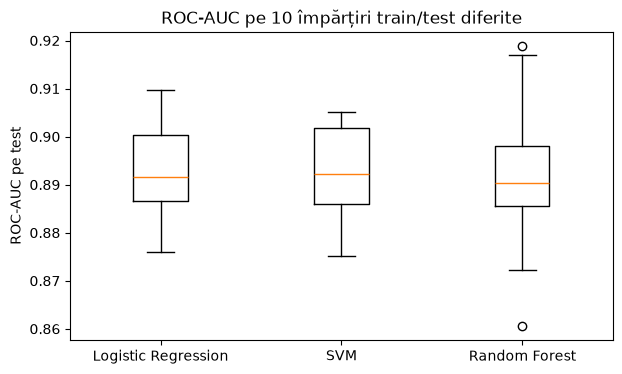

In [28]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([rulari.loc[rulari["Model"] == n, "ROC-AUC"] for n in ["Logistic Regression", "SVM", "Random Forest"]],
           tick_labels=["Logistic Regression", "SVM", "Random Forest"])
ax.set_ylabel("ROC-AUC pe test"); ax.set_title("ROC-AUC pe 10 împărțiri train/test diferite"); plt.show()

**Concluzie:** diferențele dintre modele (câteva miimi de ROC-AUC) sunt **mai mici decât variația de la o împărțire la alta** → SVM și Regresia Logistică sunt **la egalitate** (aceeași medie, aceeași variație). Random Forest are un ROC-AUC mediu asemănător, dar **recall mult mai mic și mai instabil** (deviație standard de 2–3 ori mai mare).

### 10.3 Contează preprocesarea? (experimente „cu / fără”)

Scot pe rând câte o componentă și măsor efectul în **5-fold CV pe train** (testul rămâne neatins):
- SVM **fără scalare**;
- SVM **fără `class_weight`**;
- Regresia Logistică **fără atributele noi** (`Children`, `MntTotal`, `TotalPurchases`, `PrevAccepted`).

In [29]:
from sklearn.model_selection import cross_validate

def evalueaza_cv(pipe, X_, nume):
    r = cross_validate(pipe, X_, y_train, cv=cv, scoring=["roc_auc", "recall", "f1"])
    return {"Experiment": nume, "ROC-AUC": r["test_roc_auc"].mean(), "Recall": r["test_recall"].mean(), "F1": r["test_f1"].mean()}

svm_best = cele_mai_bune["SVM"]
fara_scalare = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
noi = ["Children", "MntTotal", "TotalPurchases", "PrevAccepted"]
prep_fara_noi = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
     [c for c in num_cols if c not in noi]),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

ablatie = pd.DataFrame([
    evalueaza_cv(svm_best, X_train, "SVM – complet (ales)"),
    evalueaza_cv(Pipeline([("prep", fara_scalare), ("model", clone(svm_best.named_steps["model"]))]), X_train, "SVM – fără scalare"),
    evalueaza_cv(clone(svm_best).set_params(model__class_weight=None), X_train, "SVM – fără class_weight"),
    evalueaza_cv(cele_mai_bune["Logistic Regression"], X_train, "LogReg – complet (ales)"),
    evalueaza_cv(Pipeline([("prep", prep_fara_noi), ("model", clone(cele_mai_bune["Logistic Regression"].named_steps["model"]))]),
                 X_train.drop(columns=noi), "LogReg – fără atributele noi"),
]).set_index("Experiment")
ablatie.round(3)

,ROC-AUC,Recall,F1
Experiment,,,
SVM – complet (ales),0.902,0.779,0.579
SVM – fără scalare,0.623,0.067,0.122
SVM – fără class_weight,0.898,0.371,0.510
LogReg – complet (ales),0.904,0.805,0.584
LogReg – fără atributele noi,0.904,0.805,0.583


**Concluzie:**
- **Scalarea e esențială pentru SVM**: fără ea, `Income` (zeci de mii) domină distanțele și modelul aproape nu mai învață;
- **`class_weight` nu schimbă ROC-AUC, dar dublează aproape recall-ul** – exact efectul văzut în secțiunea 5;
- **atributele noi** aduc un câștig mic: informația exista deja în coloanele originale, atributele doar o rezumă.

### 10.4 Verificare: clienți duplicați

Setul are clienți care apar de mai multe ori (rânduri identice, cu `ID` diferit). Dacă același client e și în train și în test, scorul pe test poate fi puțin optimist (un fel de *leakage*). Verific câte rânduri din test au un „geamăn” în train și reevaluez modelul ales **fără ele**.

In [30]:
cheie = lambda d: pd.util.hash_pandas_object(d, index=False)   # o „amprentă” pentru fiecare rând
in_train = cheie(X_test).isin(set(cheie(X_train)))
print(f"Rânduri din test care apar identic și în train: {in_train.sum()} din {len(X_test)}")

m = cele_mai_bune["SVM"]
for nume, masca in [("Test complet", np.ones(len(X_test), bool)), ("Test fără duplicate", ~in_train.values)]:
    p = m.predict(X_test[masca])
    print(f"{nume:22s} ROC-AUC = {roc_auc_score(y_test[masca], scor_continuu(m, X_test[masca])):.3f} | "
          f"Recall = {recall_score(y_test[masca], p):.3f} | n = {masca.sum()}")

Rânduri din test care apar identic și în train: 74 din 448
Test complet           ROC-AUC = 0.890 | Recall = 0.761 | n = 448
Test fără duplicate    ROC-AUC = 0.909 | Recall = 0.784 | n = 374


**Concluzie:** ~16% din rândurile de test au un duplicat în train. Fără ele, scorul **nu scade** (ba chiar crește puțin) → duplicatele **nu umflă artificial** rezultatele; modelul nu le „recunoaște”, ci generalizează.

## 11. A doua întrebare: cât cheltuie un client? (regresie)

Povestea setului pune două întrebări: *cine acceptă oferta* (rezolvată mai sus) și *cât cheltuie un client*. Ținta este `MntTotal` (suma celor 6 coloane `Mnt*`, pe 2 ani).

**Data leakage:** scot din atribute toate coloanele `Mnt*` (ținta e chiar suma lor) și `Response` (rezultatul unei campanii, nu o caracteristică a clientului). Folosesc **aceeași împărțire** train/test ca la clasificare și același tip de pipeline.

Modele: **Ridge** (regresie liniară regularizată – baseline interpretabil), **SVR** (varianta SVM pentru regresie), **Random Forest Regressor** (ansamblu) + `DummyRegressor` (prezice media).
Metrică principală: **MAE** (eroarea medie, în aceleași unități ca banii cheltuiți); raportez și RMSE și R².

In [31]:
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

scoase = mnt + ["MntTotal"]
Xr_train, Xr_test = X_train.drop(columns=scoase), X_test.drop(columns=scoase)
yr_train, yr_test = X_train["MntTotal"], X_test["MntTotal"]
num_r = [c for c in num_cols if c not in scoase]

prep_r = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_r),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
cv_r = KFold(n_splits=5, shuffle=True, random_state=SEED)

modele_r = {
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1, 10, 100]}),
    "SVR": (SVR(), {"model__C": [100, 1000, 3000], "model__gamma": [0.01, 0.03, "scale"]}),
    "Random Forest Regressor": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
                                {"model__max_depth": [5, 10, None], "model__min_samples_leaf": [1, 5]}),
}
reg_rez, cele_mai_bune_r = [], {}
for nume, (model, grid) in modele_r.items():
    gs = GridSearchCV(Pipeline([("prep", prep_r), ("model", model)]), grid, cv=cv_r,
                      scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(Xr_train, yr_train)
    cele_mai_bune_r[nume] = gs.best_estimator_
    reg_rez.append({"Model": nume, "MAE CV": -gs.best_score_,
                    "Parametri": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
cele_mai_bune_r["Dummy (media)"] = Pipeline([("prep", prep_r), ("model", DummyRegressor())]).fit(Xr_train, yr_train)
reg_rez.append({"Model": "Dummy (media)",
                "MAE CV": -cross_val_score(cele_mai_bune_r["Dummy (media)"], Xr_train, yr_train, cv=cv_r,
                                           scoring="neg_mean_absolute_error").mean(), "Parametri": "-"})

for r in reg_rez:
    p = cele_mai_bune_r[r["Model"]].predict(Xr_test)
    r.update({"MAE test": mean_absolute_error(yr_test, p),
              "RMSE test": mean_squared_error(yr_test, p) ** 0.5,
              "R² test": r2_score(yr_test, p)})
tabel_reg = pd.DataFrame(reg_rez).set_index("Model").sort_values("MAE test")
print("Cheltuiala medie a unui client (test):", round(yr_test.mean(), 1))
tabel_reg.round(3)

Cheltuiala medie a unui client (test): 604.8


,MAE CV,Parametri,MAE test,RMSE test,R² test
Model,,,,,
Random Forest Regressor,110.692,"{'max_depth': None, 'min_samples_leaf': 1}",108.096,208.056,0.883
SVR,117.974,"{'C': 1000, 'gamma': 0.03}",125.999,233.935,0.853
Ridge,173.321,{'alpha': 100},172.611,272.225,0.801
Dummy (media),515.569,-,516.633,609.527,-0.000


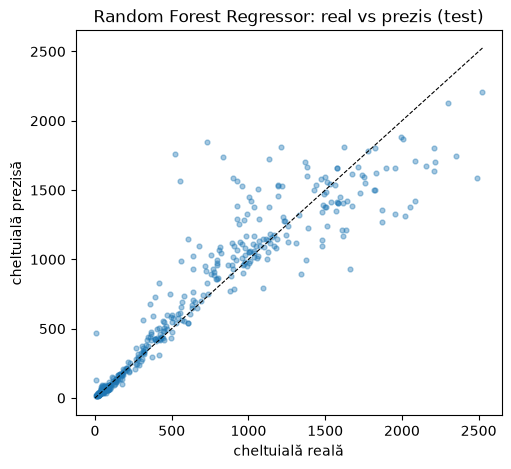

Top atribute (creșterea MAE când sunt amestecate):
TotalPurchases         218.8
Income                  86.6
NumCatalogPurchases     79.3
NumWebVisitsMonth       16.0
Customer_Days           13.5
NumWebPurchases         12.9
dtype: float64


In [32]:
best_r = tabel_reg.index[0]
p = cele_mai_bune_r[best_r].predict(Xr_test)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(yr_test, p, alpha=0.4, s=12)
ax.plot([0, yr_test.max()], [0, yr_test.max()], "k--", lw=0.8)
ax.set_xlabel("cheltuială reală"); ax.set_ylabel("cheltuială prezisă")
ax.set_title(f"{best_r}: real vs prezis (test)"); plt.show()

# ce atribute contează pentru cheltuială?
pi_r = permutation_importance(cele_mai_bune_r[best_r], Xr_test, yr_test, scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=SEED, n_jobs=-1)
print("Top atribute (creșterea MAE când sunt amestecate):")
print(pd.Series(pi_r.importances_mean, index=Xr_test.columns).sort_values(ascending=False).head(6).round(1))

**Interpretare:**
- **Random Forest Regressor** e cel mai bun: MAE ≈ 108 (față de 517 la Dummy) și **R² ≈ 0.88** → explică ~88% din diferențele de cheltuială dintre clienți. SVR e al doilea (R² ≈ 0.85), iar Ridge (liniar) e cel mai slab (R² ≈ 0.80) → aici relația **nu e liniară** și ansamblul câștigă clar;
- cele mai importante atribute: **numărul total de cumpărături**, **venitul** și **cumpărăturile din catalog**;
- atenție: numărul de cumpărături e măsurat în aceeași perioadă ca cheltuiala, deci e un predictor „ușor”; fără el problema ar fi mai grea (dar venitul singur rămâne un indicator puternic).

## 12. Contribuție originală – pe cine sunăm dacă bugetul e limitat?

În realitate firma nu își permite să contacteze toți clienții. Întrebarea practică: **dacă avem bani să sunăm doar 10%, 20%, 30% sau 50% dintre clienți, câți dintre cei interesați prindem?**

Ideea e simplă: ordonăm clienții din **test** după șansa de răspuns dată de modelul ales (Regresia Logistică) și îi sunăm de sus în jos. Comparăm cu varianta fără model: aleg clienții **la întâmplare**.

In [ ]:
model = cele_mai_bune["Logistic Regression"]       # modelul ales în capitolul 6 (grid search)
sansa = model.predict_proba(X_test)[:, 1]            # șansa de răspuns a fiecărui client din test

ordine = np.argsort(-sansa)                          # clienții de la cea mai mare șansă la cea mai mică
raspuns = y_test.to_numpy()[ordine]                  # 1 = a răspuns, 0 = nu, în ordinea de mai sus
total_interesati = raspuns.sum()                     # câți clienți din test au răspuns în total

randuri = []
for procent in [10, 20, 30, 50]:
    n = round(len(raspuns) * procent / 100)          # câți clienți sunăm
    cu_model = raspuns[:n].sum()                     # câți interesați prindem, sunând primii n
    la_intamplare = total_interesati * procent / 100 # câți am prinde alegând la întâmplare
    randuri.append({"Sunăm": f"{procent}%", "Clienți sunați": n,
                    "Interesați prinși (cu model)": cu_model,
                    "Interesați prinși (la întâmplare)": round(la_intamplare),
                    "% din toți interesații (cu model)": round(100 * cu_model / total_interesati)})

buget = pd.DataFrame(randuri).set_index("Sunăm")
print("Clienți în test:", len(raspuns), "| interesați în total:", total_interesati)
buget

Clienți în test: 448 | interesați în total: 67


,Clienți sunați,Interesați prinși (cu model),Interesați prinși (la întâmplare),% din toți interesații (cu model)
Sunăm,,,,
10%,45,31,7,46
20%,90,45,13,67
30%,134,56,20,84
50%,224,64,34,96


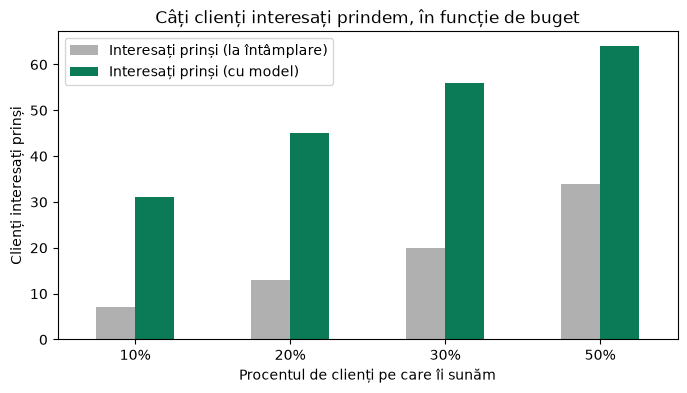

In [ ]:
buget[["Interesați prinși (la întâmplare)", "Interesați prinși (cu model)"]].plot(
    kind="bar", rot=0, figsize=(8, 4), color=["#B0B0B0", "#0B7A57"],
    title="Câți clienți interesați prindem, în funcție de buget")
plt.xlabel("Procentul de clienți pe care îi sunăm"); plt.ylabel("Clienți interesați prinși")
plt.show()

**Cum se citește:** în test sunt 448 de clienți, dintre care 67 au acceptat oferta.

- Dacă sunăm doar **10%** (45 de clienți), cu model prindem **31** de interesați; la întâmplare am prinde doar ~7 → de **4 ori mai mulți**;
- cu **20%** din buget (90 de clienți) prindem **45 din 67**, adică **două treimi** din toți interesații;
- cu **50%** din buget prindem **64 din 67** (96%) → jumătate din cheltuieli, aproape toate răspunsurile.

**Concluzie practică:** cu modelul, firma poate tăia mult bugetul campaniei și tot ajunge la majoritatea clienților interesați. Aceasta e o contribuție față de laborator: acolo am măsurat doar scoruri (ROC-AUC, recall), aici le traduc în **decizia concretă de buget**.

## 13. Concluzii

**Întrebarea 1 – Cine va accepta oferta? Da, se poate prezice destul de bine.** Am comparat Regresia Logistică, SVM și Random Forest (plus un Dummy). Am ales **Regresia Logistică (C = 1, `class_weight="balanced"`)**: ROC-AUC 0.89 pe test (0.90 în CV), găsește ~76–79% din clienții care răspund. SVM (RBF, C = 10, gamma = 0.001) a obținut aceleași scoruri, dar e mai complicat și greu de explicat; Random Forest are precizie mai mare, dar ratează jumătate din clienții interesați.

**Întrebarea 2 – Cât cheltuie un client? Da, în mare parte.** Random Forest Regressor prezice cheltuiala pe 2 ani cu o eroare medie de ~108 (R² ≈ 0.88), mult mai bine decât un model liniar (R² ≈ 0.80).

**Preprocesarea a contat:** fără scalare, SVM-ul aproape nu mai funcționează (ROC-AUC 0.62 față de 0.90). Fără tratarea dezechilibrului, recall-ul scade la jumătate (0.37 față de 0.78). Atributele noi nu au schimbat scorul (informația era deja în date). Totul fiind în pipeline, nu a existat data leakage, iar scorurile din CV s-au confirmat pe test.

**Hiperparametrii:** Regresia Logistică e stabilă pentru C ≥ 0.1; SVM e sensibil la `gamma` (prea mare → overfitting); Random Forest face overfitting (train 1.0) fără câștig pe validare peste `max_depth` = 10.

**Gradul de încredere:** pe 10 împărțiri diferite, ROC-AUC = 0.892 ± 0.010, deci rezultatele sunt stabile; diferențele dintre modele sunt mai mici decât această variație. Duplicatele din date nu au umflat scorul.

**Ce a rezultat practic:** clienții cei mai probabili să răspundă au cumpărat recent, sunt clienți vechi, cheltuie mult (mai ales pe carne), cumpără din catalog și au mai acceptat campanii.

**Ce aș face în continuare:** pragul de decizie ales după costul real al unui contact; un model de boosting; ținta de regresie transformată logaritmic (cheltuiala e foarte asimetrică).